In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
from scipy import stats
mpl.rcParams.update(mpl.rcParamsDefault)

In [ ]:
data = pd.read_csv("Students.csv")

print(data.head(10))

   gender race_ethnicity parental_level_of_education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   
5  female        group B          associate's degree      standard   
6  female        group B                some college      standard   
7    male        group B                some college  free/reduced   
8    male        group D                 high school  free/reduced   
9  female        group B                 high school  free/reduced   

  test_preparation_course  math_score  reading_score  writing_score  
0                    none          72             72             74  
1               completed          69             90             88  
2                  

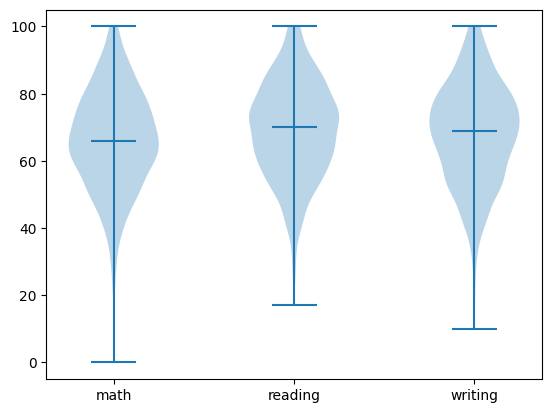

In [ ]:
plt.violinplot([data['math_score'], data['reading_score'], data['writing_score']], showmedians=True)
plt.xticks([1, 2, 3], ['math', 'reading', 'writing'])
plt.show()

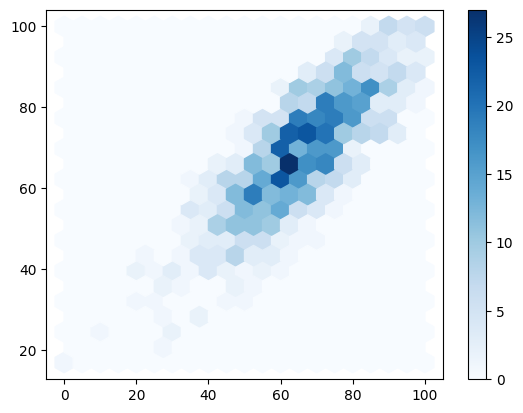

In [ ]:
plt.hexbin(data['math_score'], data['reading_score'], gridsize=20, cmap='Blues')
plt.colorbar()
plt.show()

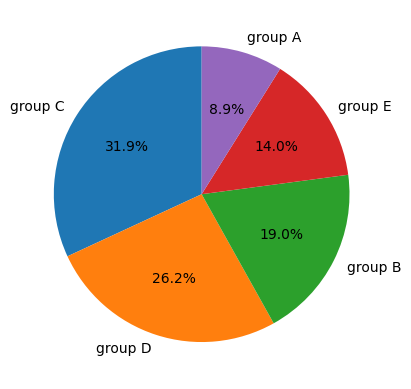

In [ ]:
counts = data['race_ethnicity'].value_counts()
plt.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90)
plt.show()

In [ ]:
data['is_passed_math_'] = np.where(data['math_score']<50, 'F', 'P')
print(f"Сдали экзамен: {len(data[data['is_passed_math_'] == 'P'])}")

Сдали экзамен: 865


In [ ]:
data['math_result'] = np.select([data['math_score'] < 25, (data['math_score'] >= 25) & (data['math_score'] <= 75), data['math_score'] > 75],['Плохо', 'Хорошо', 'Отлично'], default='Не псиал')

print(f"Сдали плохо: {len(data[data['math_result'] == 'Плохо'])}")
print(f"Сдали хорошо: {len(data[data['math_result'] == 'Хорошо'])}")
print(f"Сдали отлично: {len(data[data['math_result'] == 'Отлично'])}")
print(f"Сдали не писали: {len(data[data['math_result'] == 'Не писали'])}")

Сдали плохо: 7
Сдали хорошо: 719
Сдали отлично: 274
Сдали не писали: 0


         Плохо  Хорошо  Отлично
math         7     719      274
reading      4     652      344
writing      5     667      328


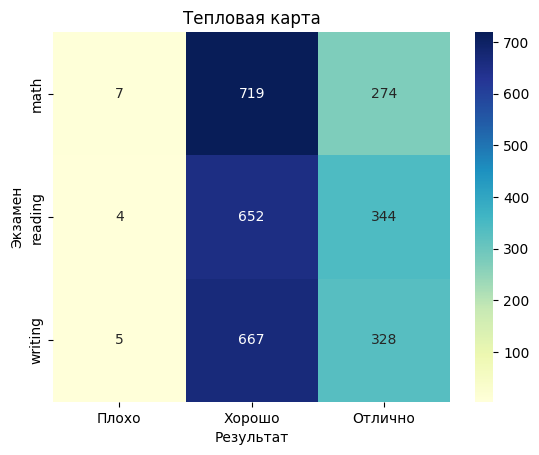

In [ ]:
data['reading_result'] = np.select([data['reading_score'] < 25, (data['reading_score'] >= 25) & (data['reading_score'] <= 75), data['reading_score'] > 75],['Плохо', 'Хорошо', 'Отлично'], default='Не псиал')
data['writing_result'] = np.select([data['writing_score'] < 25, (data['writing_score'] >= 25) & (data['writing_score'] <= 75), data['writing_score'] > 75],['Плохо', 'Хорошо', 'Отлично'], default='Не псиал')

exams = ['math', 'reading', 'writing']
categories = ['Плохо', 'Хорошо', 'Отлично']

table = pd.DataFrame([data[f'{exam}_result'].value_counts().reindex(categories, fill_value=0) for exam in exams], index=exams)
print(table)

sns.heatmap(table, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Тепловая карта')
plt.xlabel('Результат')
plt.ylabel('Экзамен')
plt.show()

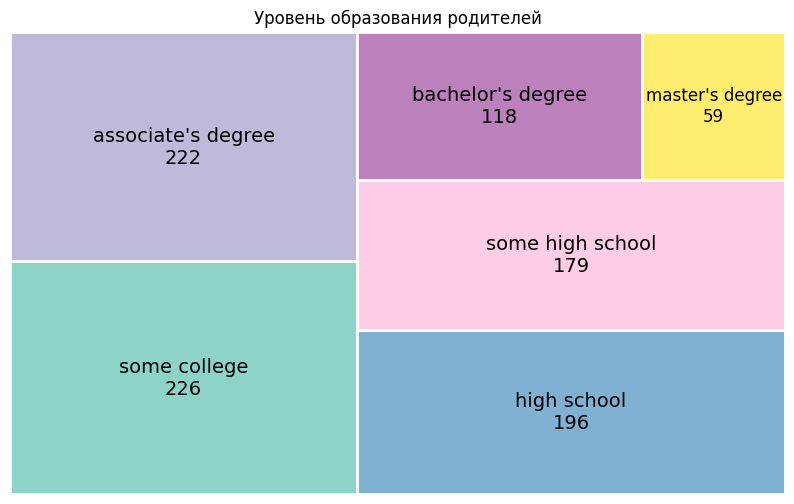

In [ ]:
import matplotlib.pyplot as plt
import mpl_extra.treemap as tr

counts = data['parental_level_of_education'].value_counts().reset_index()
counts.columns = ['education', 'count']
counts['education'] = counts['education'].astype(object)
counts['label'] = counts['education'] + '\n' + counts['count'].astype(str)

fig, ax = plt.subplots(figsize=(10, 6))
tr.treemap(ax, counts,
           area='count',
           labels='label',
           fill='education',
           cmap='Set3',
           rectprops=dict(ec='white', lw=2),
           textprops=dict(c='black', max_fontsize=14))
ax.axis('off')
plt.title('Уровень образования родителей')
plt.show()

In [ ]:
films = pd.read_csv("films.csv")
print(films.head(10))

     imdb_id  popularity     budget     revenue                original_title  \
0  tt0369610   32.985763  150000000  1513528810                Jurassic World   
1  tt1392190   28.419936  150000000   378436354            Mad Max: Fury Road   
2  tt2908446   13.112507  110000000   295238201                     Insurgent   
3  tt2488496   11.173104  200000000  2068178225  Star Wars: The Force Awakens   
4  tt2820852    9.335014  190000000  1506249360                     Furious 7   
5  tt1663202    9.110700  135000000   532950503                  The Revenant   
6  tt1340138    8.654359  155000000   440603537            Terminator Genisys   
7  tt3659388    7.667400  108000000   595380321                   The Martian   
8  tt2293640    7.404165   74000000  1156730962                       Minions   
9  tt2096673    6.326804  175000000   853708609                    Inside Out   

                                                cast  \
0  Chris Pratt|Bryce Dallas Howard|Irrfan Khan|Vi...

In [ ]:
films.info()
print(films.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1890 entries, 0 to 1889
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   imdb_id               1890 non-null   object 
 1   popularity            1890 non-null   float64
 2   budget                1890 non-null   int64  
 3   revenue               1890 non-null   int64  
 4   original_title        1890 non-null   object 
 5   cast                  1890 non-null   object 
 6   director              1890 non-null   object 
 7   tagline               1890 non-null   object 
 8   overview              1890 non-null   object 
 9   runtime               1890 non-null   int64  
 10  genres                1890 non-null   object 
 11  production_companies  1890 non-null   object 
 12  release_date          1890 non-null   object 
 13  vote_count            1890 non-null   int64  
 14  vote_average          1890 non-null   float64
 15  release_year         

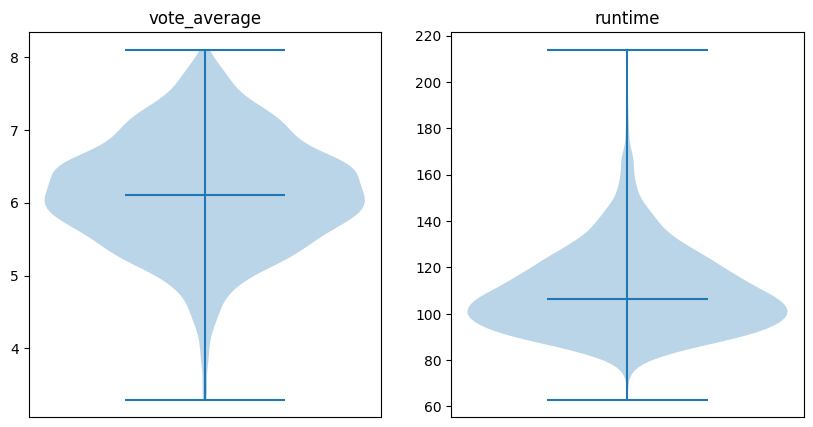

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].violinplot(films['vote_average'], showmedians=True)
axes[0].set_title('vote_average')
axes[0].set_xticks([])

axes[1].violinplot(films['runtime'], showmedians=True)
axes[1].set_title('runtime')
axes[1].set_xticks([])

plt.show()

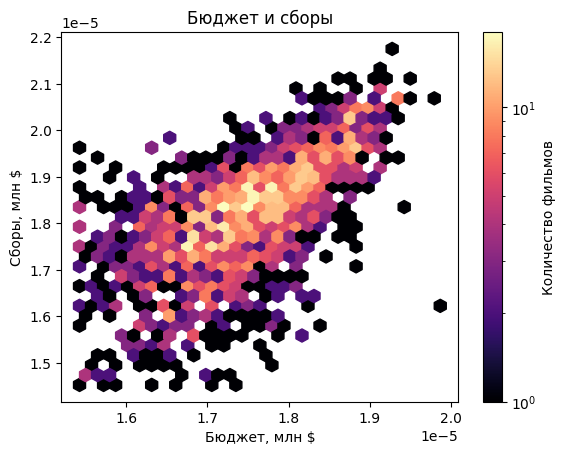

In [ ]:
films['log_budget'] = np.log1p(films['budget'])
films['log_revenue'] = np.log1p(films['revenue'])

plt.hexbin(films['log_budget'] / 1e6, films['log_revenue'] / 1e6, gridsize=30, cmap='magma', bins='log')
plt.colorbar(label='Количество фильмов')
plt.xlabel('Бюджет, млн $')
plt.ylabel('Сборы, млн $')
plt.title('Бюджет и сборы')
plt.show()

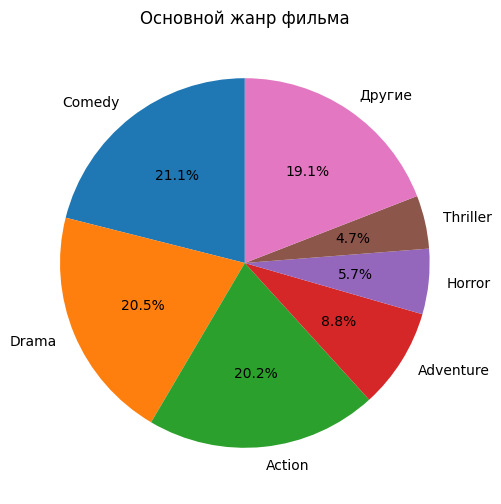

In [ ]:
films['main_genre'] = films['genres'].str.split('|').str[0]

counts = films['main_genre'].value_counts()
top = counts.head(6)
top['Другие'] = counts.iloc[6:].sum()

plt.figure(figsize=(6, 6))
plt.pie(top, labels=top.index, autopct='%1.1f%%', startangle=90)
plt.title('Основной жанр фильма')
plt.show()

In [ ]:
films['is_profitable'] = np.where(films['revenue'] > films['budget'], 'Окупился', 'Не окупился')

print(f"Окупились: {len(films[films['is_profitable'] == 'Окупился'])}")
print(f"Не окупились: {len(films[films['is_profitable'] == 'Не окупился'])}")

Окупились: 1478
Не окупились: 412


In [ ]:
films['rating_result'] = np.select(
    [films['vote_average'] < 5.5,
     (films['vote_average'] >= 5.5) & (films['vote_average'] <= 7),
     films['vote_average'] > 7],
    ['Плохо', 'Хорошо', 'Отлично'],
    default='Нет оценки'
)
print(films['rating_result'].value_counts())

rating_result
Хорошо     1315
Плохо       336
Отлично     239
Name: count, dtype: int64


rating_result  Плохо  Хорошо  Отлично
period                               
2000–2004        105     339       61
2005–2009        121     441       68
2010–2015        110     535      110


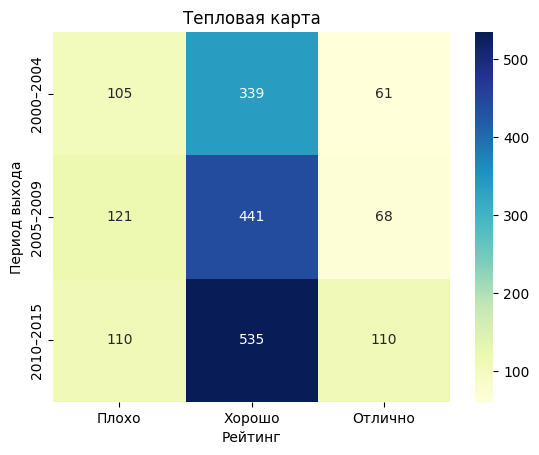

In [ ]:
films['period'] = np.select(
    [films['release_year'] <= 2004,
     (films['release_year'] >= 2005) & (films['release_year'] <= 2009),
     films['release_year'] >= 2010],
    ['2000–2004', '2005–2009', '2010–2015'],
    default='Другое'
)

table = pd.crosstab(films['period'], films['rating_result'])
table = table[['Плохо', 'Хорошо', 'Отлично']]
print(table)

sns.heatmap(table, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Тепловая карта')
plt.xlabel('Рейтинг')
plt.ylabel('Период выхода')
plt.show()

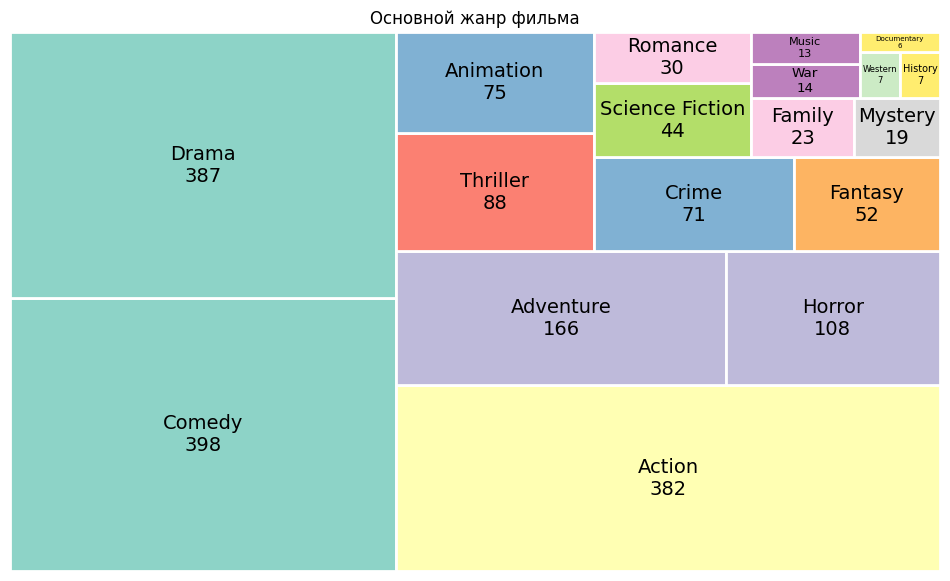

In [ ]:
counts = films['main_genre'].value_counts().reset_index()
counts.columns = ['genre', 'count']
counts['genre'] = counts['genre'].astype(object)
counts['label'] = counts['genre'] + '\n' + counts['count'].astype(str)

fig, ax = plt.subplots(figsize=(12, 7))
tr.treemap(ax, counts, area='count', labels='label', fill='genre', cmap='Set3',
           rectprops=dict(ec='white', lw=2),
           textprops=dict(c='black', max_fontsize=14))
ax.axis('off')
plt.title('Основной жанр фильма')
plt.show()